# 08 · Fairness of the policy as deployed, and sizing a store trial

Two questions before the business case:

1. **Is any group of honest shoppers stopped unfairly often** under the recommended policy, as it
   would actually run (shoppers respond, trust updates over four cycles, 10 runs)?
2. **How many stores would a randomised trial need** to confirm the headline in real stores?

Both are computed by `python -m smartshop.reporting.snapshot`; this notebook reads its outputs.
Demographics are joined only here, never in a model or the policy.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle

set_style()
fair = pd.read_csv('../models/fairness.csv').set_index('attribute')
groups = pd.read_csv('../models/fairness_groups.csv')
sizing = pd.read_csv('../models/trial_sizing.csv').set_index('between-store CV')
snap = json.load(open('../dashboards/snapshot/snapshot.json'))

## 1. Honest-shopper stop rates

The adverse outcome is being asked for a full rescan **when honest**. For every attribute: the
four-fifths ratio (lowest group rate / highest), an interval that resamples households, the ratio
if every group had the same basket sizes, and a **permutation test**: the ratio random groups of
the same sizes would show. With up to 11 groups of as few as 11 households, the lowest/highest
ratio sits well below 1 by chance alone, so the raw ratio on its own over-reports unfairness.

In [2]:
cols = ['groups', 'fewest households in a group', 'four-fifths ratio', 'ratio CI low', 'ratio CI high',
        'ratio, same basket sizes', 'ratio if groups were random (median)', 'chance of a gap this large',
        'highest rate vs today', 'verdict']
fair[cols].round(3)

,groups,fewest households in a group,four-fifths ratio,ratio CI low,ratio CI high,"ratio, same basket sizes",ratio if groups were random (median),chance of a gap this large,highest rate vs today,verdict
attribute,,,,,,,,,,
channel,2,1040,0.960,0.886,0.998,0.978,0.974,0.303,0.319,pass
new SmartShop user (<5 sessions),2,693,0.979,0.856,0.998,0.915,0.971,0.670,0.318,pass
evening peak,2,2026,0.996,0.935,0.999,0.994,0.969,0.927,0.312,pass
age group,6,46,0.611,0.497,0.674,0.761,0.803,0.010,0.376,review
household size,5,53,0.636,0.515,0.725,0.808,0.836,0.000,0.452,gap explained by basket size
income level,11,11,0.595,0.418,0.664,0.758,0.613,0.420,0.422,gap within chance for groups this small


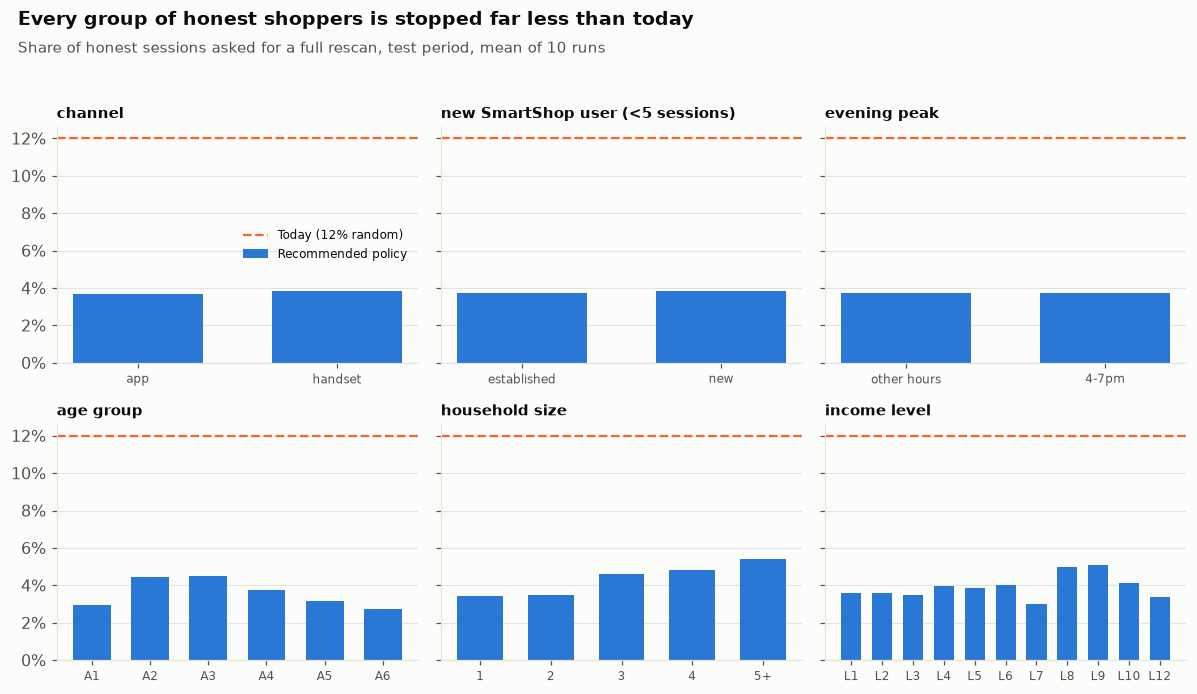

In [3]:
import re

names = {'False': 'established', 'True': 'new', '0.0': 'other hours', '1.0': '4-7pm'}
order = lambda g: [int(x) for x in re.findall(r'\d+', g)] or [0]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharey=True)
for ax, (attr, d) in zip(axes.flat, groups.groupby('attribute', sort=False)):
    d = d.iloc[sorted(range(len(d)), key=lambda i: (order(d.group.iloc[i]), d.group.iloc[i]))]
    ax.bar(range(len(d)), d.policy, color=BLUE, width=0.65, label='Recommended policy')
    ax.axhline(d.today.iloc[0], color=ORANGE, lw=1.5, ls='--', label="Today (12% random)")
    labels = [names.get(g, g.replace('Age Group', 'A').replace('Level', 'L')) for g in d.group]
    ax.set_xticks(range(len(d)), labels, fontsize=8)
    ax.set_title(attr, fontsize=10, pad=6)
    ax.yaxis.set_major_formatter(pct())
    ax.grid(axis='x', visible=False)
axes.flat[0].legend(frameon=False, fontsize=8, loc='center right')
fig.suptitle('Every group of honest shoppers is stopped far less than today', x=0.02, ha='left',
             fontweight='bold', fontsize=12.5)
fig.text(0.02, 0.92, 'Share of honest sessions asked for a full rescan, test period, mean of 10 runs',
         color=TEXT_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, '20_fairness_groups')
fig

**Reading it.**

- **Channel, new SmartShop users, evening peak: pass** (ratios 0.96–1.0). The week 5 fixes hold
  once trust and shopper responses are included; trust does not disadvantage new users, because
  without history they simply get the standard rate.
- **Income: the gap is within chance.** Random groups this small give a ratio of about 0.61; the
  observed 0.60 is no worse.
- **Household size: a real gap, explained by basket size.** Larger households buy bigger baskets,
  and bigger baskets carry more risk for everyone; at equal basket sizes the ratio is 0.81.
- **Age: a real gap that basket size only partly explains** (0.61, or 0.76 at equal basket sizes;
  random groups would give about 0.80). The drivers are basket-level features: the basket model's
  expected missing value, basket value and number of products. Younger households (age groups 2–3)
  buy the largest baskets.

**In absolute terms no group is worse off than today:** the most-stopped group in any attribute is
stopped at 31–45% of today's rate. The remaining review item is relative: whether a business is
content that younger family households are stopped about 1.6x as often as the oldest when honest,
because their baskets are bigger. That is a policy decision for the business, and the trial below
is where it would be monitored (Nectar's consented demographic data, aggregated).

## 2. Sizing a store-level randomised trial

The simulator cannot prove the headline for real stores. A trial can: randomise stores (matched in
pairs on baseline loss rate) to today's random rescans or the recommended policy at the same
colleague time, and compare each store's loss rate over the trial period, adjusted for its own
baseline period (CUPED / ANCOVA).

**Measuring loss in both arms the same way** is the point of week 8: each arm keeps random full
rescans (today's 2% random full rescans; the policy's 2% floor), and each store's loss is estimated
from them. The error of that estimate is not assumed: the random floor gave a 15% error over the
whole test period (47,314 sessions, 30 runs, as in week 8), and it scales with one over the square
root of sessions. For a store with 20,000 SmartShop sessions in the trial period that is about 23%,
which is why measurement noise, not only the spread between stores, drives the trial size.

The spread of loss rates between real stores, and how stable a store's loss rate is from one period
to the next (rho), cannot be estimated from simulated stores (too few households each), so the
table shows a range. Stores per arm to detect the 12% headline with 80% power at 5% significance:

In [4]:
print(f"measurement error per store: {snap['trial']['measurement_cv']:.0%}")
sizing

measurement error per store: 23%


,total CV,rho=0.0,rho=0.5,rho=0.7,rho=0.85
between-store CV,,,,,
0.15,0.272179,81,61,42,23
0.25,0.337760,125,94,64,35
0.35,0.417231,190,143,97,53


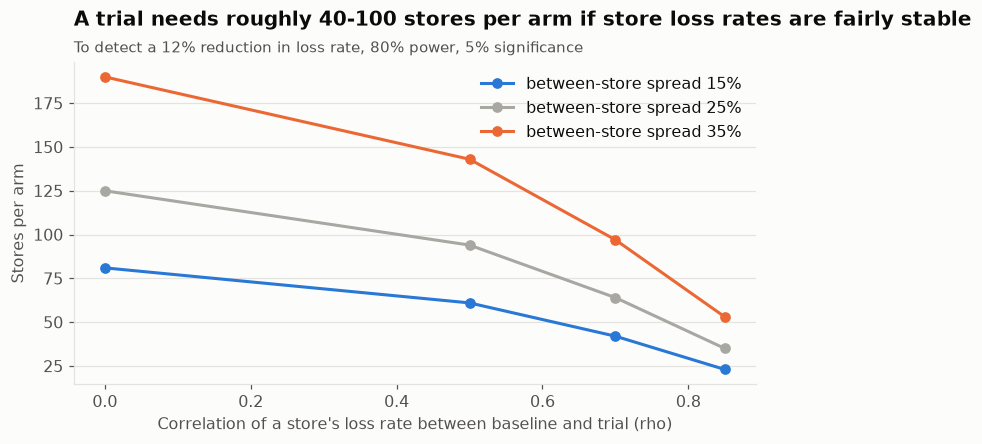

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
rhos = [c for c in sizing.columns if c.startswith('rho=')]
x = [float(c.split('=')[1]) for c in rhos]
for cv, color in zip(sizing.index, [BLUE, GREY, ORANGE]):
    ax.plot(x, sizing.loc[cv, rhos], marker='o', color=color, label=f'between-store spread {cv:.0%}')
ax.set_xlabel('Correlation of a store\'s loss rate between baseline and trial (rho)')
ax.set_ylabel('Stores per arm')
ax.legend(frameon=False)
ax.set_title('A trial needs roughly 40-100 stores per arm if store loss rates are fairly stable')
subtitle(ax, 'To detect a 12% reduction in loss rate, 80% power, 5% significance')
save(fig, '21_trial_sizing')
fig

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Channel, new users and evening peak pass the four-fifths rule (0.96–1.0) under the policy as deployed | The week 5 fixes hold with trust and responding shoppers |
| 2 | Every group of honest shoppers is stopped at 31–45% of today's rate | No group is worse off than today in absolute terms |
| 3 | Income: gap within chance (random groups this small give 0.61; observed 0.60). Household size: explained by basket size (0.81 at equal sizes) | Not unfairness, given how few households the groups hold |
| 4 | Age: younger family households stopped about 1.6x as often as the oldest when honest; basket size explains part (0.76) | **Review item**: a business decision, monitored in the trial |
| 5 | A store trial needs roughly 40–100 stores per arm (matched pairs, baseline adjustment, rho = 0.7), more if store loss rates are unstable; measurement noise from the 2% random audit (about 23% per store) is a large part of it | Feasible for a chain of ~600 supermarkets; a longer trial period or a larger random audit share cuts the stores needed |